# Replicating Goldrick et al. (2019) with Penicillium

> S. Goldrick, C. A. Duran-Villalobos, K. Jankauskas, D. Lovett, S. S. Farid, B. Lennox. *Modern day monitoring
> and control challenges outlined on an industrial-scale benchmark fermentation process.* Computers and Chemical
> Engineering 130 (2019) 106471. [doi:10.1016/j.compchemeng.2019.05.037](https://doi.org/10.1016/j.compchemeng.2019.05.037)

The paper presents IndPenSim as a benchmark: five yearly production campaigns (Table 2), a simulated Raman
analyser (Fig. 2), Raman-based soft sensors (Figs. 3 and 6), an advanced control (APC) case study that raises
yields by 20 %, and a fault-detection case study (Fig. 7). This notebook repeats those simulations with
`penicillium` and puts our results next to the paper's.

| Paper | What it shows | Here |
|---|---|---|
| Table 2 | Yields of five 26-batch campaigns | Replicated (campaigns 2 and 3 with an assumed batch-length distribution) |
| Fig. 2 | Building blocks of the simulated Raman spectra | Replicated |
| Fig. 3 | Raman PLS soft sensor for penicillin, with substrate disturbances | Replicated |
| Fig. 4 | Feed and concentration profiles of campaign 5 | Replicated |
| Fig. 6 | Raman PLS soft sensor for PAA, and PAA control with it (APC) | Replicated, plus the APC campaign |
| Fig. 7 | Nominal and faulty batches of campaign 4 | Replicated |
| Figs. 5, 8-10 | PLS / PCA analyses of the campaign data | Not repeated here (analyses on top of the data, not simulations) |

**What cannot match exactly.** IndPenSim draws each batch's random parameters from MATLAB's random number
generator; Penicillium uses NumPy's, so batch *n* here is not batch *n* of the paper. Compare distributions
(means, spreads, numbers of failed batches) and the shapes of the profiles, not individual batches.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import CubicSpline
from scipy.signal import savgol_filter
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import KFold, cross_val_predict

import penicillium
from penicillium import BatchSpec, Fault, RamanMode, SimulationConfig, Simulator, raman, simulate_batches
from penicillium.simulator import pid_controller

print("penicillium", penicillium.__version__)

N_BATCHES = 26  # batches per campaign, as in the paper
TARGET_KG = 2000  # batches below this are "below target"
N_JOBS = None  # worker processes for campaigns (None: all CPUs)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titlelocation": "left"})

penicillium 0.1.0.dev0


## 1. Operating modes

The paper's campaigns combine two choices (Section 1.1 and Table 2):

* **Control strategy.** *Recipe driven*: sugar and PAA feeds follow the fixed recipe. *Operator dependant*: from
  95 h the operators hold the feeds and step them up or down every 20 h. In IndPenSim this is the PRBS option
  (`SimulationConfig(prbs=True)`): steps of ±15 L/h on the sugar feed and ±1 L/h on the PAA feed at 120, 140,
  ... h.
* **Batch length.** *Fixed* at 230 h, or *variable*, depending on downstream delays.

None of the five campaigns used advanced control, so PAA is fed by the recipe (`RamanMode.RECORD` or `OFF`, which
give the same process; `OFF` skips computing spectra). The **APC** campaign of Section 5.1 controls PAA with a
Raman soft sensor, rebuilt in Section 5 below.

**Variable batch length.** The paper gives only the mean and spread (239 ± 27 h and 239 ± 32 h). We draw lengths
from a normal distribution with those values, rounded to the 0.2 h sample time and clipped to 200-320 h. This is
an assumption; the distribution actually used is not published.

In [2]:
def variable_lengths(mean, sd, n, seed):
    rng = np.random.default_rng(seed)
    return np.clip(np.round(rng.normal(mean, sd, n) / 0.2) * 0.2, 200, 320)


CAMPAIGNS = {
    # name: (control strategy, PRBS, batch lengths, paper's Table 2 values)
    "Campaign 1": ("Operator dependant", True, [230.0] * N_BATCHES,
                   dict(length="230 ± 0", n=26, below=2, mean=2882, sd=745, annual=74939)),
    "Campaign 2": ("Recipe driven", False, variable_lengths(239, 27, N_BATCHES, 2),
                   dict(length="239 ± 27", n=25, below=8, mean=2578, sd=769, annual=64458)),
    "Campaign 3": ("Operator dependant", True, variable_lengths(239, 32, N_BATCHES, 3),
                   dict(length="239 ± 32", n=26, below=6, mean=2950, sd=888, annual=76690)),
    "Campaign 4": ("Recipe driven", False, [230.0] * N_BATCHES,
                   dict(length="230 ± 0", n=26, below=2, mean=2912, sd=786, annual=75716)),
    "Campaign 5": ("Operator dependant", True, [230.0] * N_BATCHES,
                   dict(length="230 ± 0", n=26, below=5, mean=2816, sd=796, annual=73228)),
}  # fmt: skip


def campaign_specs(index, prbs, lengths, raman_mode=RamanMode.OFF):
    return [
        BatchSpec(seed=1000 * index + i, config=SimulationConfig(prbs=prbs, batch_length_h=float(length),
                                                                   raman_mode=raman_mode))
        for i, length in enumerate(lengths, start=1)
    ]  # fmt: skip


t0 = time.perf_counter()
campaign_results = {}
for index, (name, (_strategy, prbs, lengths, _paper)) in enumerate(CAMPAIGNS.items(), start=1):
    campaign_results[name] = simulate_batches(campaign_specs(index, prbs, lengths), n_jobs=N_JOBS)
n_total = sum(len(r) for r in campaign_results.values())
print(f"Simulated {n_total} batches in {time.perf_counter() - t0:.0f} s")

Simulated 130 batches in 50 s


## 2. Table 2: yearly campaigns

The penicillin yield of a batch is the penicillin harvested during the batch (broth discharges) plus the
penicillin in the vessel at harvest, as IndPenSim computes it. The paper labels annual production "kg × 10³",
but its values are the sum of the batch yields in kg (26 × 2912 kg ≈ 75,716 kg), so that is what we compare.

In [3]:
def campaign_row(results, lengths):
    y = np.array([r.total_yield for r in results])
    return {
        "batch length [h]": f"{np.mean(lengths):.0f} ± {np.std(lengths, ddof=1):.0f}",
        "batches": len(results),
        "below target": int(np.sum(y < TARGET_KG)),
        "yield per batch [kg]": f"{y.mean():.0f} ± {y.std(ddof=1):.0f}",
        "annual production [kg]": f"{y.sum():,.0f}",
    }


def paper_row(p):
    return {
        "batch length [h]": p["length"],
        "batches": p["n"],
        "below target": p["below"],
        "yield per batch [kg]": f"{p['mean']} ± {p['sd']}",
        "annual production [kg]": f"{p['annual']:,}",
    }


rows = {}
for name, (strategy, _prbs, lengths, paper) in CAMPAIGNS.items():
    rows[(name, strategy, "paper")] = paper_row(paper)
    rows[(name, strategy, "Penicillium")] = campaign_row(campaign_results[name], lengths)
table2 = pd.DataFrame(rows).T
table2.index.names = ["campaign", "control strategy", "source"]
table2

batch length [h] batches  \
campaign   control strategy   source                                   
Campaign 1 Operator dependant paper                  230 ± 0      26   
                              Penicillium          230 ± 0      26   
Campaign 2 Recipe driven      paper                 239 ± 27      25   
                              Penicillium         241 ± 20      26   
Campaign 3 Operator dependant paper                 239 ± 32      26   
                              Penicillium         240 ± 30      26   
Campaign 4 Recipe driven      paper                  230 ± 0      26   
                              Penicillium          230 ± 0      26   
Campaign 5 Operator dependant paper                  230 ± 0      26   
                              Penicillium          230 ± 0      26   

                                            below target yield per batch [kg]  \
campaign   control strategy   source                                            
Campaign 1 Operator dependant paper                    2           2882 ± 745   
                              Penicillium            3           2940 ± 736   
Campaign 2 Recipe driven      paper                    8           2578 ± 769   
                              Penicillium            4           2999 ± 880   
Campaign 3 Operator dependant paper                    6           2950 ± 888   
                              Penicillium            4          3147 ± 1049   
Campaign 4 Recipe driven      paper                    2           2912 ± 786   
                              Penicillium            2           2745 ± 752   
Campaign 5 Operator dependant paper                    5           2816 ± 796   
                              Penicillium            2           3198 ± 728   

                                            annual production [kg]  
campaign   control strategy   source                                
Campaign 1 Operator dependant paper                         74,939  
                              Penicillium                 76,439  
Campaign 2 Recipe driven      paper                         64,458  
                              Penicillium                 77,963  
Campaign 3 Operator dependant paper                         76,690  
                              Penicillium                 81,823  
Campaign 4 Recipe driven      paper                         75,716  
                              Penicillium                 71,365  
Campaign 5 Operator dependant paper                         73,228  
                              Penicillium                 83,152

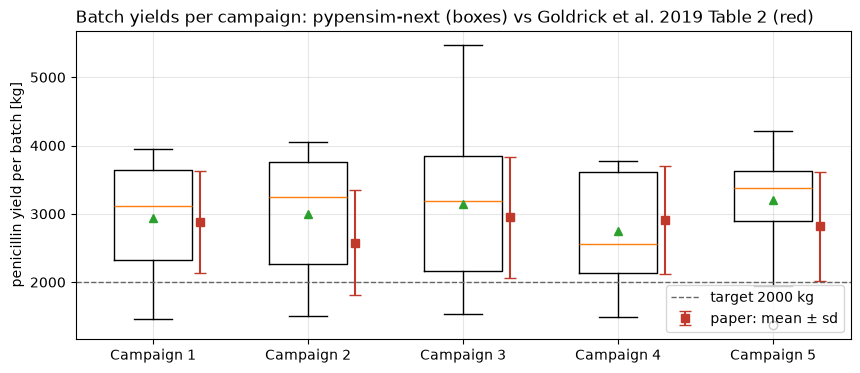

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
data = [[r.total_yield for r in campaign_results[name]] for name in CAMPAIGNS]
ax.boxplot(data, tick_labels=list(CAMPAIGNS), showmeans=True)
for i, (*_, paper) in enumerate(CAMPAIGNS.values(), start=1):
    ax.errorbar(
        i + 0.3,
        paper["mean"],
        yerr=paper["sd"],
        fmt="s",
        color="#c0392b",
        capsize=4,
        label="paper: mean ± sd" if i == 1 else None,
    )
ax.axhline(TARGET_KG, color="0.4", ls="--", lw=1, label="target 2000 kg")
ax.set_ylabel("penicillin yield per batch [kg]")
ax.set_title("Batch yields per campaign: Penicillium (boxes) vs Goldrick et al. 2019 Table 2 (red)")
ax.legend(loc="lower right")
plt.show()

## 3. Fig. 4: profiles of campaign 5

Campaign 5 is operator dependant with a fixed 230 h batch length. The paper shows the sugar and PAA feeds and
the offline biomass and penicillin measurements of all 26 batches, with the below-target batches dashed red.

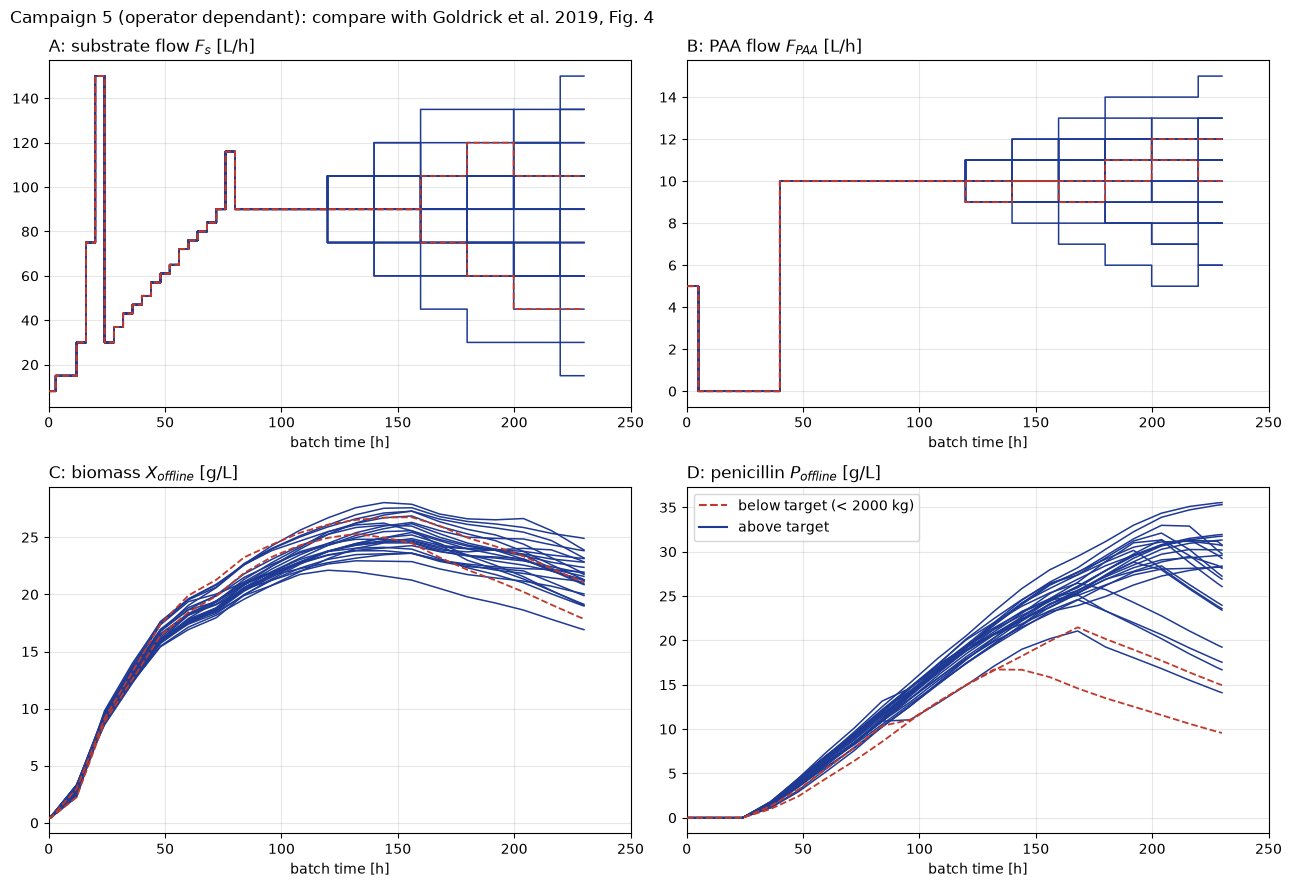

2 of 26 batches below target (paper: 5 of 26)


In [5]:
c5 = campaign_results["Campaign 5"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
panels = [
    ("Fs", "A: substrate flow $F_s$ [L/h]", False),
    ("Fpaa", "B: PAA flow $F_{PAA}$ [L/h]", False),
    ("X_offline", "C: biomass $X_{offline}$ [g/L]", True),
    ("P_offline", "D: penicillin $P_{offline}$ [g/L]", True),
]
for ax, (name, title, offline) in zip(axes.flat, panels, strict=True):
    for r in c5:
        failed = r.total_yield < TARGET_KG
        t, v = r.time, r[name]
        if offline:
            keep = ~np.isnan(v)
            t, v = np.concatenate([[0], t[keep]]), np.concatenate([[v[keep][0]], v[keep]])
        style = dict(color="#c0392b", ls="--", lw=1.3, zorder=3) if failed else dict(color="#1f3a93", lw=1.1)
        ax.plot(t, v, drawstyle="steps-pre" if not offline else "default", **style)
    ax.set_title(title)
    ax.set_xlim(0, 250)
    ax.set_xlabel("batch time [h]")
axes[1, 1].plot([], [], color="#c0392b", ls="--", label="below target (< 2000 kg)")
axes[1, 1].plot([], [], color="#1f3a93", label="above target")
axes[1, 1].legend(loc="upper left")
fig.suptitle("Campaign 5 (operator dependant): compare with Goldrick et al. 2019, Fig. 4", x=0.01, ha="left")
fig.tight_layout()
plt.show()
n_failed = sum(r.total_yield < TARGET_KG for r in c5)
print(f"{n_failed} of {len(c5)} batches below target (paper: 5 of 26)")

**Compared with the paper's Fig. 4.** The feeds follow the same recipe up to 95 h and the same operator steps
from 120 h (±15 L/h on $F_s$, ±1 L/h on $F_{PAA}$). Biomass peaks at 22-29 g/L around 130-150 h and then declines,
penicillin reaches 20-35 g/L, and the below-target batches separate after ~150 h, when their penicillin starts
to fall. That matches the paper.

## 4. Fig. 7: nominal and faulty batches of campaign 4

The paper builds its normal operating conditions (NOC) from campaign 4 (recipe driven, fixed length): it drops
the 2 below-target batches and 5 "sub-optimal" ones, leaving 17 NOC batches. It then adds four batches with
faults. We drop the below-target batches and, as the sub-optimal ones are not identified, the lowest-yield
remaining batches, to keep 17.

**Which faults.** IndPenSim's fault codes are in the `Fault` enum. The aeration, pH sensor and substrate faults
of Fig. 7A-C match `AERATION`, `PH_SENSOR` and `SUBSTRATE_FEED` exactly (same samples and values in the MATLAB
code). The "coolant fault" of Fig. 7D is a slow temperature rise from ~100 h. IndPenSim's coolant flow fault
(`COOLANT_FLOW`) is instead a 20 h loss of cooling at 70-90 h, while the temperature sensor fault
(`TEMPERATURE_SENSOR`, a +0.4 K drift between 40 and 160 h) produces exactly the rise of Fig. 7D. We use the
latter, and plot the coolant flow fault afterwards for comparison.

In [6]:
c4 = campaign_results["Campaign 4"]
order = np.argsort([r.total_yield for r in c4])[::-1]
noc = [c4[i] for i in order[:17]]
print(f"NOC: 17 batches, yields {min(r.total_yield for r in noc):.0f}-{max(r.total_yield for r in noc):.0f} kg")

FIG7_FAULTS = {
    "Fault 1-Aeration": Fault.AERATION,
    "Fault 2-pH": Fault.PH_SENSOR,
    "Fault 3-Substrate": Fault.SUBSTRATE_FEED,
    "Fault 4-Coolant": Fault.TEMPERATURE_SENSOR,
}
fault_specs = [BatchSpec(seed=4100 + i, config=SimulationConfig(fault=f, raman_mode=RamanMode.OFF))
               for i, f in enumerate(FIG7_FAULTS.values(), start=1)]  # fmt: skip
faulty = dict(zip(FIG7_FAULTS, simulate_batches(fault_specs, n_jobs=N_JOBS), strict=True))
for name, r in faulty.items():
    print(f"{name:<18} yield {r.total_yield:6.0f} kg, final penicillin {r['P'][-1]:5.1f} g/L")

NOC: 17 batches, yields 2226-3781 kg


Fault 1-Aeration   yield    828 kg, final penicillin   5.7 g/L
Fault 2-pH         yield   2040 kg, final penicillin  14.6 g/L
Fault 3-Substrate  yield    571 kg, final penicillin   4.0 g/L
Fault 4-Coolant    yield   3822 kg, final penicillin  32.1 g/L


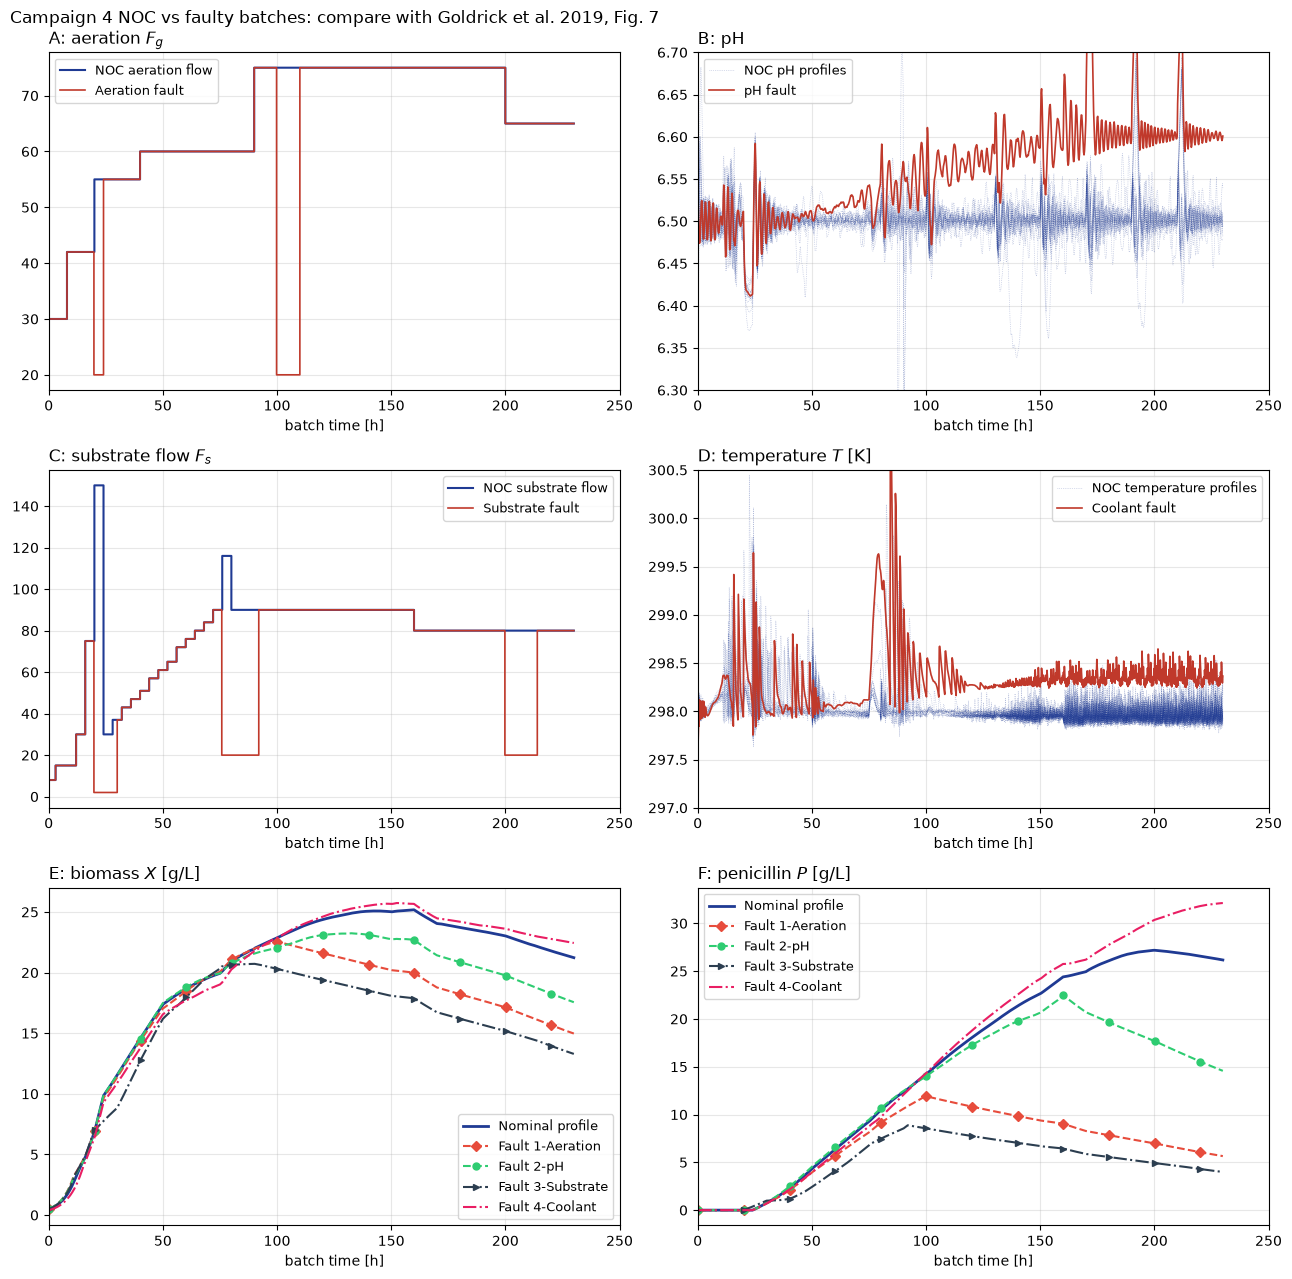

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
t = noc[0].time
panels = [
    ("Fg", "Fault 1-Aeration", "A: aeration $F_g$", "NOC aeration flow"),
    ("pH", "Fault 2-pH", "B: pH", "NOC pH profiles"),
    ("Fs", "Fault 3-Substrate", "C: substrate flow $F_s$", "NOC substrate flow"),
    ("T", "Fault 4-Coolant", "D: temperature $T$ [K]", "NOC temperature profiles"),
]
for ax, (name, fault, title, noc_label) in zip(axes.flat[:4], panels, strict=True):
    if name in ("Fg", "Fs"):  # identical recipe in all NOC batches: plot one
        ax.plot(t, noc[0][name], color="#1f3a93", drawstyle="steps-pre", label=noc_label)
    else:
        for i, r in enumerate(noc):
            ax.plot(r.time, r[name], color="#1f3a93", lw=0.5, alpha=0.35, ls=":", label=noc_label if i == 0 else None)
    ax.plot(
        faulty[fault].time,
        faulty[fault][name],
        color="#c0392b",
        lw=1.2,
        label=fault.split("-")[1] + " fault",
        drawstyle="steps-pre" if name in ("Fg", "Fs") else "default",
    )
    ax.set_title(title)
    ax.legend(loc="best", fontsize=9)
axes[0, 1].set_ylim(6.3, 6.7)
axes[1, 1].set_ylim(297, 300.5)
styles = {
    "Fault 1-Aeration": ("#e74c3c", "--", "D"),
    "Fault 2-pH": ("#2ecc71", "--", "o"),
    "Fault 3-Substrate": ("#2c3e50", "-.", ">"),
    "Fault 4-Coolant": ("#e91e63", "-.", None),
}
for ax, name, title in [(axes[2, 0], "X", "E: biomass $X$ [g/L]"), (axes[2, 1], "P", "F: penicillin $P$ [g/L]")]:
    ax.plot(t, np.mean([r[name] for r in noc], axis=0), color="#1f3a93", lw=2, label="Nominal profile")
    for fault, r in faulty.items():
        color, ls, marker = styles[fault]
        ax.plot(r.time, r[name], color=color, ls=ls, marker=marker, markevery=100, ms=5, label=fault)
    ax.set_title(title)
    ax.legend(fontsize=9)
for ax in axes.flat:
    ax.set_xlim(0, 250)
    ax.set_xlabel("batch time [h]")
fig.suptitle("Campaign 4 NOC vs faulty batches: compare with Goldrick et al. 2019, Fig. 7", x=0.01, ha="left")
fig.tight_layout()
plt.show()

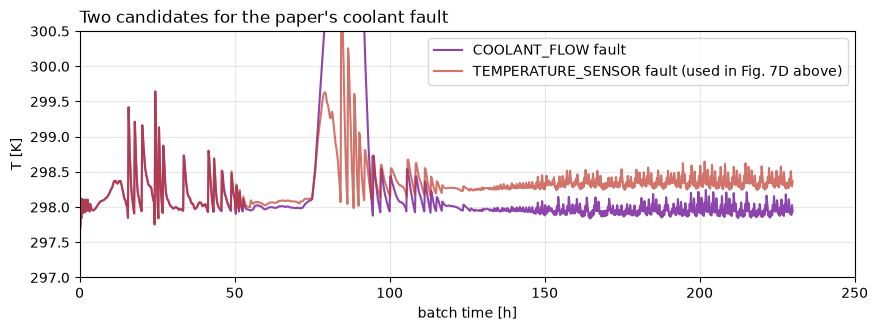

In [8]:
# The other candidate for "coolant fault": IndPenSim's coolant flow fault (Fc forced to 2 L/h at samples 350-450).
alt = Simulator(config=SimulationConfig(fault=Fault.COOLANT_FLOW, raman_mode=RamanMode.OFF)).run(seed=4104)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(alt.time, alt["T"], color="#8e44ad", label="COOLANT_FLOW fault")
ax.plot(
    faulty["Fault 4-Coolant"].time,
    faulty["Fault 4-Coolant"]["T"],
    color="#c0392b",
    alpha=0.7,
    label="TEMPERATURE_SENSOR fault (used in Fig. 7D above)",
)
ax.set(
    xlim=(0, 250),
    ylim=(297, 300.5),
    xlabel="batch time [h]",
    ylabel="T [K]",
    title="Two candidates for the paper's coolant fault",
)
ax.legend()
plt.show()

**Compared with the paper's Fig. 7 (A-D).** The aeration fault drops $F_g$ to 20 at 20-24 h and 100-110 h; the
substrate fault cuts $F_s$ at 20-30 h, 76-92 h and 200-214 h; the pH sensor drift pushes the real pH up to ~6.6;
the temperature drift raises $T$ by ~0.4 K. Nominal biomass peaks at ~25 g/L around 150 h, as in Fig. 7E.

**Effect on penicillin (E-F).** The paper shows one batch per fault, and so do the panels above. Batch-to-batch
variation is large (the nominal final titre ranges from about 12 to 34 g/L), so a single batch says little. The
next cell simulates every fault on the same 26 seeds and compares the average effect with the paper's single
batches.

In [9]:
PAPER_FINAL_P = {"Fault 1-Aeration": 7, "Fault 2-pH": 31, "Fault 3-Substrate": 13.5, "Fault 4-Coolant": 18}
FAULT_STATS = {"No fault (nominal)": (Fault.NONE, 28.5)}
FAULT_STATS.update({name: (fault, PAPER_FINAL_P[name]) for name, fault in FIG7_FAULTS.items()})
FAULT_STATS["Coolant flow fault"] = (Fault.COOLANT_FLOW, None)
seeds = range(4001, 4001 + N_BATCHES)
rows = {}
for name, (fault, paper_p) in FAULT_STATS.items():
    res = simulate_batches([BatchSpec(seed=s, config=SimulationConfig(fault=fault, raman_mode=RamanMode.OFF))
                            for s in seeds], n_jobs=N_JOBS)  # fmt: skip
    p_end = np.array([r["P"][-1] for r in res])
    y = np.array([r.total_yield for r in res])
    rows[name] = {
        "fault code": fault.name,
        "paper: final P of its one batch [g/L]": "-" if paper_p is None else f"~{paper_p}",
        "final P, mean [g/L]": round(p_end.mean(), 1),
        "final P, range [g/L]": f"{p_end.min():.1f}-{p_end.max():.1f}",
        "yield, mean [kg]": round(y.mean()),
        "below target": f"{np.sum(y < TARGET_KG)}/{len(y)}",
    }
pd.DataFrame(rows).T

,fault code,paper: final P of its one batch [g/L],"final P, mean [g/L]","final P, range [g/L]","yield, mean [kg]",below target
No fault (nominal),NONE,~28.5,22.2,10.6-32.6,2745,2/26
Fault 1-Aeration,AERATION,~7,9.5,5.9-20.5,1343,25/26
Fault 2-pH,PH_SENSOR,~31,22.0,10.7-32.0,2755,2/26
Fault 3-Substrate,SUBSTRATE_FEED,~13.5,9.7,3.7-28.3,1276,22/26
Fault 4-Coolant,TEMPERATURE_SENSOR,~18,22.0,10.5-32.6,2725,4/26
Coolant flow fault,COOLANT_FLOW,-,22.3,10.6-32.9,2754,3/26


Paper values are read from Fig. 7F (±1 g/L). On average the **aeration** and **substrate** faults cost about half
of the final titre and push most batches below target, as in the paper, and the **pH sensor** fault changes
almost nothing. The paper's **coolant** batch lost ~10 g/L, but neither IndPenSim fault that involves cooling
does that here: the temperature sensor drift (+0.4 K) and the coolant flow fault leave the average titre
unchanged. The paper notes that penicillin only drops once $T$ exceeds ~298.5 K, and its Fig. 7D reaches
~298.7 K, while a 0.4 K drift stays below that. The published code does not tell which fault, or which fault
size, the paper's batch used.

## 5. Raman spectroscopy, soft sensors and advanced control

### Fig. 2: simulated Raman spectra

Each spectrum is the reference spectrum (B), plus Gaussian peaks for substrate, PAA and penicillin scaled by
their concentrations (C), plus random-walk noise (D), plus a fluorescence baseline that grows with penicillin,
biomass, viscosity and time. E shows the result for one batch, one spectrum per 12 min.

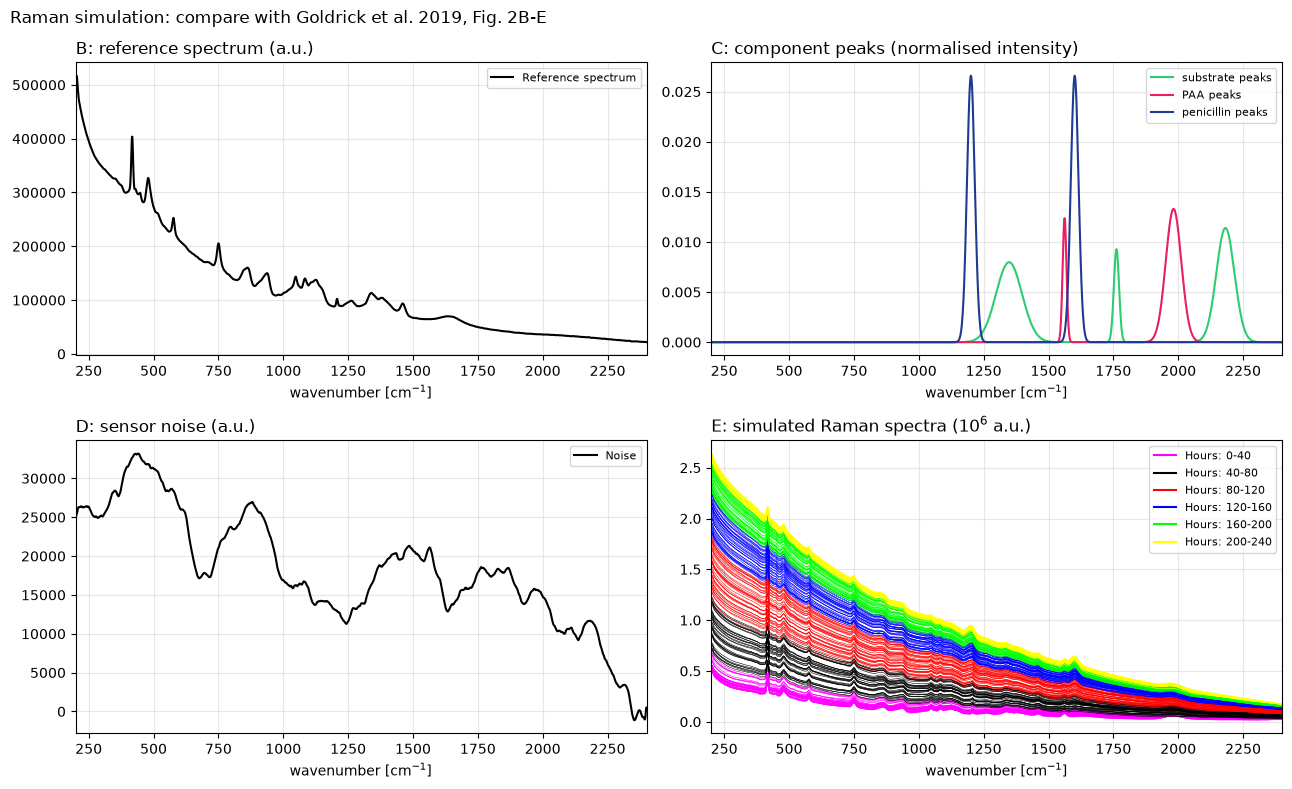

In [10]:
cal = Simulator().run(seed=101)  # recipe driven, Raman recorded (the default)
wn = raman.WAVENUMBER
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(wn, raman.REFERENCE_SPECTRUM, color="k", label="Reference spectrum")
axes[0, 0].set_title("B: reference spectrum (a.u.)")
colors = {"substrate": "#2ecc71", "PAA": "#e91e63", "penicillin": "#1f3a93"}
for name, shape in raman.PEAK_SHAPES.items():
    axes[0, 1].plot(wn, shape, color=colors[name], label=f"{name} peaks")
axes[0, 1].set_title("C: component peaks (normalised intensity)")
axes[1, 0].plot(wn, raman.baseline_noise(np.random.default_rng(0)), color="k", label="Noise")
axes[1, 0].set_title("D: sensor noise (a.u.)")
bins = [
    (0, 40, "magenta"),
    (40, 80, "k"),
    (80, 120, "red"),
    (120, 160, "blue"),
    (160, 200, "lime"),
    (200, 240, "yellow"),
]
for lo, hi, color in bins:
    rows = np.flatnonzero((cal.time > max(lo, 2.0)) & (cal.time <= hi))
    for i in rows[::5]:
        axes[1, 1].plot(wn, cal.raman[i] / 1e6, color=color, lw=0.4)
    axes[1, 1].plot([], [], color=color, label=f"Hours: {lo}-{hi}")
axes[1, 1].set_title("E: simulated Raman spectra (10$^6$ a.u.)")
for ax in axes.flat:
    ax.set_xlabel("wavenumber [cm$^{-1}$]")
    ax.set_xlim(200, 2400)
    ax.legend(fontsize=8)
fig.suptitle("Raman simulation: compare with Goldrick et al. 2019, Fig. 2B-E", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### Soft sensor recipe (Section 4 of the paper)

A partial least squares (PLS) model maps pre-processed spectra to a concentration:

* spectral region: 1540-1580 and 1950-2050 cm⁻¹ for PAA (the paper's choice); for penicillin the paper does not
  give the region, so we use 250-2250 cm⁻¹;
* pre-processing: Savitzky-Golay smoothing over 15 points with the first derivative;
* response: the offline lab measurements, interpolated to every spectrum with a cubic spline. Lab results
  describe the broth 4 samples (0.8 h) before they are reported, so they are placed at that earlier time;
* number of latent variables: by cross-validation. The paper uses leave-one-out; we use 10 contiguous blocks,
  which is much faster and avoids neighbouring, nearly identical spectra leaking between training and test
  data. We take the smallest model within 5 % of the best cross-validated error. As in the paper, each model is
  calibrated on a single batch, so this cross-validation is within one batch: it estimates the error on
  that batch, not on a new one. The validation and test batches below are the figures to read.

In [11]:
def region_mask(*regions):
    mask = np.zeros(wn.size, bool)
    for lo, hi in regions:
        mask |= (wn >= lo) & (wn <= hi)
    return mask


PAA_REGION = region_mask((1540, 1580), (1950, 2050))
P_REGION = region_mask((250, 2250))


def preprocess(spectra, mask):
    d = savgol_filter(np.atleast_2d(spectra), window_length=15, polyorder=2, deriv=1, axis=1)
    return d[:, mask]


def spectra_and_lab(result, lab, mask):
    rows = np.flatnonzero(np.any(result.raman != 0, axis=1))  # no spectra in the first 2 h
    keep = ~np.isnan(result[lab])
    y = CubicSpline(result.time[keep] - 0.8, result[lab][keep])(result.time[rows])
    return preprocess(result.raman[rows], mask), y, rows


def fit_soft_sensor(result, lab, mask, max_lv=10):
    X, y, _ = spectra_and_lab(result, lab, mask)
    cv = KFold(10)
    rmse = [np.sqrt(np.mean((cross_val_predict(PLSRegression(n, scale=False), X, y, cv=cv).ravel() - y) ** 2))
            for n in range(1, max_lv + 1)]  # fmt: skip
    n_lv = next(i + 1 for i, e in enumerate(rmse) if e <= 1.05 * min(rmse))
    return PLSRegression(n_lv, scale=False).fit(X, y), n_lv, rmse


def predict(model, result, mask):
    rows = np.flatnonzero(np.any(result.raman != 0, axis=1))
    return result.time[rows], model.predict(preprocess(result.raman[rows], mask)).ravel()

### Fig. 3: penicillin soft sensor during substrate disturbances

The paper calibrates a penicillin PLS model on one batch, validates it on a second, and then tests it on two
batches with disturbances in the substrate feed, where penicillin falls. Calibration and validation batches
carry PRBS steps on the feeds (as in the paper); the disturbed batches use IndPenSim's substrate fault.

penicillin PLS model: 2 latent variables
Calibration batch      RMSE of the prediction vs true penicillin: 0.24 g/L
Validation batch       RMSE of the prediction vs true penicillin: 0.24 g/L


Process disturbance 1  RMSE of the prediction vs true penicillin: 0.24 g/L
Process disturbance 2  RMSE of the prediction vs true penicillin: 0.24 g/L


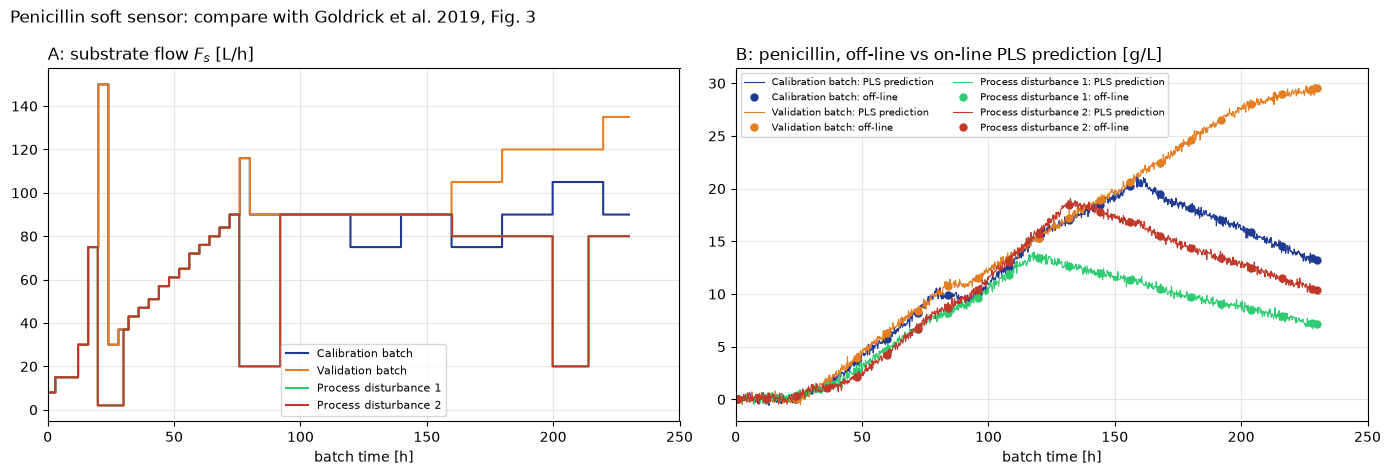

In [12]:
fig3 = {
    "Calibration batch": SimulationConfig(prbs=True),
    "Validation batch": SimulationConfig(prbs=True),
    "Process disturbance 1": SimulationConfig(fault=Fault.SUBSTRATE_FEED),
    "Process disturbance 2": SimulationConfig(fault=Fault.SUBSTRATE_FEED),
}
fig3_results = dict(zip(fig3, simulate_batches([BatchSpec(seed=300 + i, config=c) for i, c in enumerate(fig3.values())],
                                               n_jobs=N_JOBS), strict=True))  # fmt: skip
p_model, p_lv, _ = fit_soft_sensor(fig3_results["Calibration batch"], "P_offline", P_REGION)
print(f"penicillin PLS model: {p_lv} latent variables")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colors = ["#1f3a93", "#e67e22", "#2ecc71", "#c0392b"]
for color, (name, r) in zip(colors, fig3_results.items(), strict=True):
    axes[0].plot(r.time, r["Fs"], color=color, drawstyle="steps-pre", label=name)
    t_pred, y_pred = predict(p_model, r, P_REGION)
    axes[1].plot(t_pred, y_pred, color=color, lw=0.8, label=f"{name}: PLS prediction")
    lab = ~np.isnan(r["P_offline"])
    axes[1].plot(r.time[lab], r["P_offline"][lab], "o", color=color, ms=5, label=f"{name}: off-line")
    rmse = np.sqrt(np.mean((y_pred - r["P"][-len(y_pred) :]) ** 2))
    print(f"{name:<22} RMSE of the prediction vs true penicillin: {rmse:.2f} g/L")
axes[0].set(title="A: substrate flow $F_s$ [L/h]", xlabel="batch time [h]", xlim=(0, 250))
axes[1].set(title="B: penicillin, off-line vs on-line PLS prediction [g/L]", xlabel="batch time [h]", xlim=(0, 250))
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=7, ncol=2)
fig.suptitle("Penicillin soft sensor: compare with Goldrick et al. 2019, Fig. 3", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### Fig. 6: PAA soft sensor and PAA control (APC)

Following the PAT framework of Section 5.1: a **calibration** batch builds the PAA model, a **validation** batch
tests it on-line, and an **APC** batch uses it in closed loop. The paper's controller:

* a PI loop on the PAA feed $F_{PAA}$, switched on after 25 h, set-point 1250 mg/L;
* fed with the soft-sensor signal filtered by a 3-point moving average.

The paper does not give the PI gains. IndPenSim's built-in PAA controller ($K_p = 0.1$, $T_i = 0.5$ h) is tuned
for the noise-free true concentration; on the noisy soft-sensor signal it moves $F_{PAA}$ between 0 and 15 L/h
every few samples. We detune it to $K_p = 0.02$, $T_i = 1$ h (velocity form, output 0-150 L/h), which gives
smooth feed moves like the paper's Fig. 6B. The APC loop runs sample by sample through `Simulator.step`,
replacing the recipe's $F_{PAA}$ with the controller output.

In [13]:
cal = Simulator().run(seed=101)
val = Simulator().run(seed=102)
paa_model, paa_lv, paa_rmse = fit_soft_sensor(cal, "PAA_offline", PAA_REGION)
print(f"PAA PLS model: {paa_lv} latent variables; CV RMSE by number of LVs: {np.round(paa_rmse, 1)} mg/L")


def run_apc(seed, model=paa_model, setpoint=1250.0, start_h=25.0, Kp=0.02, Ti=1.0):
    # One batch with PAA controlled from the Raman soft sensor. Returns the result and the soft-sensor trace.
    sim = Simulator()
    sim.reset(seed)
    times, preds, errors, fpaa_prev = [], [], [], None
    while not sim.done:
        u = sim.recipe_inputs()
        spectrum = sim.latest_spectrum()
        if spectrum is not None:
            times.append(sim.time)
            preds.append(float(model.predict(preprocess(spectrum, PAA_REGION)).ravel()[0]))
        if sim.time >= start_h and len(preds) >= 3:
            error = setpoint - np.mean(preds[-3:])  # 3-point moving average of the soft sensor
            errors.append(error)
            previous = fpaa_prev if fpaa_prev is not None else u["Fpaa"]
            u["Fpaa"] = pid_controller(previous, error, errors[-2] if len(errors) > 1 else error,
                                       0, 0, 0, 0.0, 150.0, Kp, Ti, 0.0, 0.2)  # fmt: skip
        fpaa_prev = u["Fpaa"]
        sim.step(**u)
    return sim.result(), (np.array(times), np.array(preds))


apc, (apc_t, apc_pred) = run_apc(seed=103)
after = apc.time > 30
print(
    f"APC batch: PAA after 30 h {apc['PAA'][after].mean():.0f} ± {apc['PAA'][after].std():.0f} mg/L "
    f"(set-point 1250); yield {apc.total_yield:.0f} kg"
)

PAA PLS model: 5 latent variables; CV RMSE by number of LVs: [138.5  51.4  33.8  32.6  32.   31.7  31.7  31.1  30.9  30.7] mg/L


APC batch: PAA after 30 h 1259 ± 25 mg/L (set-point 1250); yield 3244 kg


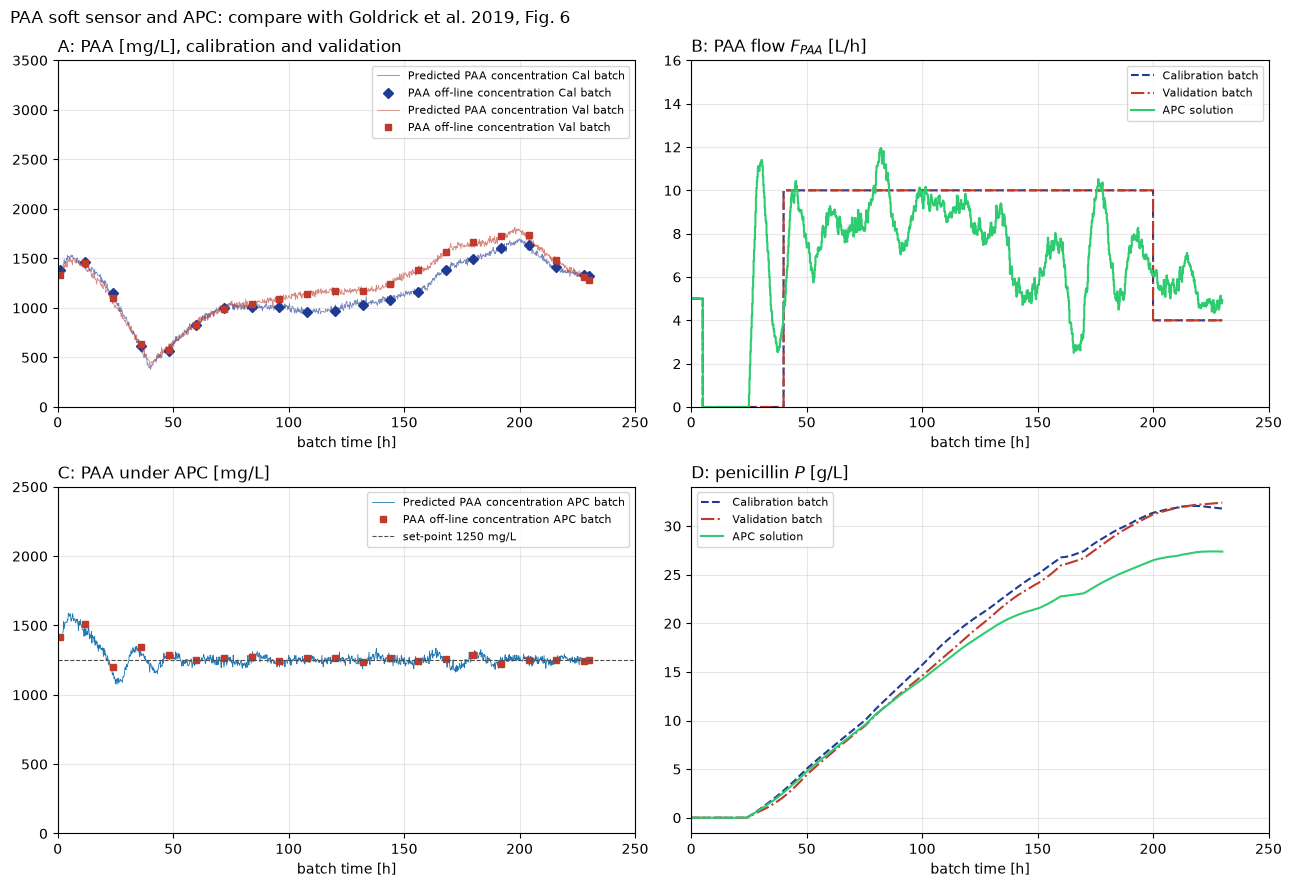

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for r, name, color in [(cal, "Cal", "#1f3a93"), (val, "Val", "#c0392b")]:
    t_pred, y_pred = predict(paa_model, r, PAA_REGION)
    axes[0, 0].plot(t_pred, y_pred, color=color, lw=0.6, alpha=0.6, label=f"Predicted PAA concentration {name} batch")
    lab = ~np.isnan(r["PAA_offline"])
    axes[0, 0].plot(
        r.time[lab],
        r["PAA_offline"][lab],
        "s" if name == "Val" else "D",
        color=color,
        ms=5,
        label=f"PAA off-line concentration {name} batch",
    )
axes[0, 0].set(title="A: PAA [mg/L], calibration and validation", ylim=(0, 3500))
for r, name, style in [
    (cal, "Calibration batch", dict(color="#1f3a93", ls="--")),
    (val, "Validation batch", dict(color="#c0392b", ls="-.")),
    (apc, "APC solution", dict(color="#2ecc71")),
]:
    axes[0, 1].plot(r.time, r["Fpaa"], drawstyle="steps-pre", label=name, **style)
    axes[1, 1].plot(r.time, r["P"], label=name, **style)
axes[0, 1].set(title="B: PAA flow $F_{PAA}$ [L/h]", ylim=(0, 16))
lab = ~np.isnan(apc["PAA_offline"])
axes[1, 0].plot(apc_t, apc_pred, color="#1f78b4", lw=0.6, label="Predicted PAA concentration APC batch")
axes[1, 0].plot(
    apc.time[lab], apc["PAA_offline"][lab], "s", color="#c0392b", ms=5, label="PAA off-line concentration APC batch"
)
axes[1, 0].axhline(1250, color="0.3", lw=0.8, ls="--", label="set-point 1250 mg/L")
axes[1, 0].set(title="C: PAA under APC [mg/L]", ylim=(0, 2500))
axes[1, 1].set(title="D: penicillin $P$ [g/L]")
for ax in axes.flat:
    ax.set(xlim=(0, 250), xlabel="batch time [h]")
    ax.legend(fontsize=8)
fig.suptitle("PAA soft sensor and APC: compare with Goldrick et al. 2019, Fig. 6", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### APC campaign

The paper ran the APC solution for a year: 26 batches, **3517 ± 315 kg** per batch, none below target, a 20 %
increase over the five campaigns. We run 26 batches with the soft-sensor APC above (sample by sample, so in this
process; about a minute). For reference we also run IndPenSim's built-in PAT mode
(`RamanMode.PAT_CONTROL`), which controls PAA from the *true* concentration at 1200 mg/L from 10 h: an idealised
upper bound for a perfect sensor.

In [15]:
t0 = time.perf_counter()
apc_campaign = [run_apc(seed=6000 + i)[0] for i in range(1, N_BATCHES + 1)]
pat = SimulationConfig(raman_mode=RamanMode.PAT_CONTROL)
ideal = simulate_batches(
    [BatchSpec(seed=6000 + i, config=pat) for i in range(1, N_BATCHES + 1)], n_jobs=N_JOBS, keep_raman=False
)
recipe_same_seeds = simulate_batches([BatchSpec(seed=6000 + i, config=SimulationConfig(raman_mode=RamanMode.OFF))
                                      for i in range(1, N_BATCHES + 1)], n_jobs=N_JOBS)  # fmt: skip
print(f"{3 * N_BATCHES} batches in {time.perf_counter() - t0:.0f} s")

five = np.concatenate([[r.total_yield for r in res] for res in campaign_results.values()])
rows = {
    ("APC (Raman soft sensor)", "paper"): {"yield per batch [kg]": "3517 ± 315", "below target": 0,
                                           "increase vs campaigns 1-5": "20 %"},
}  # fmt: skip
for name, results in [
    ("APC (Raman soft sensor)", apc_campaign),
    ("PAT mode (true PAA, ideal sensor)", ideal),
    ("same seeds, recipe only", recipe_same_seeds),
]:
    y = np.array([r.total_yield for r in results])
    rows[(name, "Penicillium")] = {
        "yield per batch [kg]": f"{y.mean():.0f} ± {y.std(ddof=1):.0f}",
        "below target": int(np.sum(y < TARGET_KG)),
        "increase vs campaigns 1-5": f"{100 * (y.mean() / five.mean() - 1):.0f} %",
    }
apc_table = pd.DataFrame(rows).T
apc_table.index.names = ["campaign", "source"]
apc_table

78 batches in 109 s


yield per batch [kg]  \
campaign                          source                               
APC (Raman soft sensor)           paper                   3517 ± 315   
                                  Penicillium           3445 ± 193   
PAT mode (true PAA, ideal sensor) Penicillium           3445 ± 193   
same seeds, recipe only           Penicillium           2658 ± 695   

                                                below target  \
campaign                          source                       
APC (Raman soft sensor)           paper                    0   
                                  Penicillium            0   
PAT mode (true PAA, ideal sensor) Penicillium            0   
same seeds, recipe only           Penicillium            4   

                                                increase vs campaigns 1-5  
campaign                          source                                   
APC (Raman soft sensor)           paper                              20 %  
                                  Penicillium                      15 %  
PAT mode (true PAA, ideal sensor) Penicillium                      15 %  
same seeds, recipe only           Penicillium                     -12 %

**Why the APC works, and why it matches the ideal controller.** In the model, PAA enters the kinetics through
two steep switches: penicillin production stops below ~200 mg/L, and biomass growth is inhibited above
~2400 mg/L (`tanh` terms with critical values 200 and 2400 mg/L). Between the two, PAA has no effect. Batches
fed by the recipe fail when PAA accumulates above 2400 mg/L: that is the "critical process parameter" the paper
finds with PLS (Fig. 5B). Any controller that keeps PAA inside the band, from a soft sensor or from the true
value, gives practically the same batch, which is why the two controlled campaigns above have the same yields.

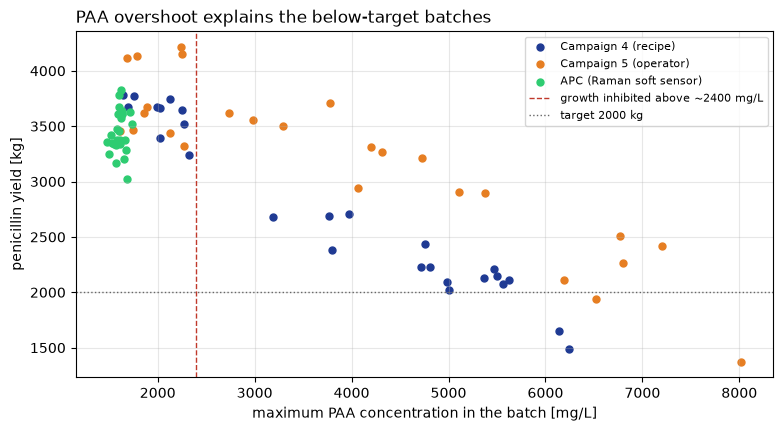

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for results, label, color in [
    (campaign_results["Campaign 4"], "Campaign 4 (recipe)", "#1f3a93"),
    (campaign_results["Campaign 5"], "Campaign 5 (operator)", "#e67e22"),
    (apc_campaign, "APC (Raman soft sensor)", "#2ecc71"),
]:
    ax.scatter([r["PAA"].max() for r in results], [r.total_yield for r in results], s=25, color=color, label=label)
ax.axvline(2400, color="#c0392b", ls="--", lw=1, label="growth inhibited above ~2400 mg/L")
ax.axhline(TARGET_KG, color="0.4", ls=":", lw=1, label="target 2000 kg")
ax.set(
    xlabel="maximum PAA concentration in the batch [mg/L]",
    ylabel="penicillin yield [kg]",
    title="PAA overshoot explains the below-target batches",
)
ax.legend(fontsize=8)
plt.show()

## 6. Summary

The tables and figures above put each result next to the paper's. In short:

* **Campaign yields (Table 2).** For the fixed-length campaigns, means and spreads are within about two standard
  errors of the paper's (the standard error of a difference between two 26-batch means is ≈ 210 kg), and the
  numbers of below-target batches are similar. The
  variable-length campaigns depend on the assumed batch-length distribution; campaign 2 (recipe driven, variable)
  comes out clearly better here than in the paper (8 below-target batches there).
* **Profiles (Figs. 4 and 7).** Feeds, biomass and penicillin follow the same shapes and ranges, and the faults
  act at the same times. Averaged over 26 batches, the aeration and substrate faults cost as much penicillin as
  in the paper and the pH sensor fault as little; the paper's coolant fault is not reproduced by either cooling
  fault of the published code.
* **Raman, soft sensors and APC (Figs. 2, 3, 6).** The simulated spectra have the same structure and intensity
  range; PLS soft sensors built the paper's way track penicillin and PAA; PAA control from the soft sensor holds
  PAA at its set-point, and the APC campaign gains ~15 % in mean yield (paper: 20 %) with no below-target batches.

Remaining differences come from the random streams (MATLAB vs NumPy), the assumed batch-length distribution of
campaigns 2 and 3, the unspecified PI gains, details of the PLS models, and the coolant fault.